# E1 · Stage 1：11 维 DQN 基线（Colab 复刻）

本 notebook 复刻 `log.md` 中的 **E1**。原始命令：

```bash
OMP_NUM_THREADS=4 python scripts/train_dqn.py \
  --episodes 500 --eval-every 50 --eval-episodes 20 --final-eval-episodes 100 \
  --checkpoint-every 100 --log-every 25 --output-dir runs/stage1_seed0
```

| 项 | 值 |
| --- | --- |
| 观察 | 11 维手工特征 |
| 网络 | MLP 11 → 256 → 3 |
| 算法 | 普通 DQN（无目标网络、无 Double、MSE） |
| replay | 100k，batch 1000，每步 short-memory + 每局 long-memory |
| epsilon | 0.4 → 0，80 局 |
| 训练 | 500 局，seed 0，CPU |
| 评估 | 训练中每 50 局跑 20 局；最终 100 局 @ 20000+i；独立复核 100 局 @ 10000+i |

**本地参考结果（log.md）**：20k mean **27.14**，10k mean **27.21**。

> Colab 的 CPU 型号、线程数和 PyTorch 版本与本地不同，不保证逐位复现；
> 这里验证的是配置、流程和结果量级。


In [ ]:
#@title 1. 解压项目 & 安装依赖
import os, sys, subprocess, pathlib

os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
os.environ["OMP_NUM_THREADS"] = "4"

CONTENT = pathlib.Path("/content")
PROJECT = CONTENT / "snake_rl"
TARBALL = CONTENT / "snake_rl_colab.tar.gz"

if not (PROJECT / "pyproject.toml").exists():
    if not TARBALL.exists():
        raise FileNotFoundError(
            f"缺少 {TARBALL}，请先在本地用 colab upload 上传项目压缩包"
        )
    subprocess.run(["tar", "xzf", str(TARBALL), "-C", str(CONTENT)], check=True)

os.chdir(PROJECT)
print("cwd             =", os.getcwd())
print("python          =", sys.version.split()[0])
print("cpu count       =", os.cpu_count())
print("OMP_NUM_THREADS =", os.environ["OMP_NUM_THREADS"])

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-e", "."],
    check=True,
)

import torch
print("torch           =", torch.__version__)
print("cuda            =", torch.cuda.is_available())


cwd             = /content/snake_rl
python          = 3.13.18
cpu count       = 2
OMP_NUM_THREADS = 4


torch           = 2.11.0+cpu
cuda            = False


In [ ]:
#@title 2. 训练 E1（500 局，CPU，seed 0）
import os, subprocess, sys, time

cmd = [
    sys.executable, "scripts/train_dqn.py",
    "--episodes", "500",
    "--eval-every", "50",
    "--eval-episodes", "20",
    "--final-eval-episodes", "100",
    "--checkpoint-every", "100",
    "--log-every", "25",
    "--output-dir", "runs/stage1_seed0_colab",
]

print("command:", " ".join(cmd))
t0 = time.perf_counter()
subprocess.run(cmd, check=True, env={**os.environ, "OMP_NUM_THREADS": "4"})
print(f"\ntraining wall time: {time.perf_counter() - t0:.1f}s")


command: /usr/bin/python3 scripts/train_dqn.py --episodes 500 --eval-every 50 --eval-episodes 20 --final-eval-episodes 100 --checkpoint-every 100 --log-every 25 --output-dir runs/stage1_seed0_colab



training wall time: 264.3s


In [ ]:
#@title 3. 独立复核：10k 评估种子（100 局 greedy）
import subprocess, sys

subprocess.run(
    [
        sys.executable, "scripts/evaluate.py",
        "--run-dir", "runs/stage1_seed0_colab",
        "--episodes", "100",
        "--seed", "10000",
        "--device", "cpu",
    ],
    check=True,
)


CompletedProcess(args=['/usr/bin/python3', 'scripts/evaluate.py', '--run-dir', 'runs/stage1_seed0_colab', '--episodes', '100', '--seed', '10000', '--device', 'cpu'], returncode=0)

In [ ]:
#@title 4. 结果汇总与 log.md 对照
import json, pathlib

run = pathlib.Path("runs/stage1_seed0_colab")
summary = json.loads((run / "summary.json").read_text())
final_20k = json.loads((run / "final_eval.json").read_text())
eval_10k = json.loads((run / "eval.json").read_text())
config = json.loads((run / "config.json").read_text())


def line(name, r):
    endings = " ".join(f"{k}={v}" for k, v in sorted(r["endings"].items()))
    return (
        f"{name:<10} mean={r['mean_score']:6.2f}  median={r['median_score']:5.1f}  "
        f"max={r['max_score']:3d}  min={r['min_score']:3d}  std={r['std_score']:5.2f}  "
        f"steps={r['mean_steps']:6.1f}  score/step={r['score_per_step']:.4f}  "
        f"endings[{endings}]"
    )


print("== 最终评估 ==")
print(line("colab-20k", final_20k))
print(line("colab-10k", eval_10k))
print()
print("log.md E1 参考: 20k mean=27.14 / 10k mean=27.21")
print()
print("== 训练成本 ==")
print(f"steps          : {summary['train_steps']}")
print(f"wall time      : {summary['train_seconds']:.1f}s")
print(f"steps/s        : {summary['steps_per_second']:.1f}")
print(f"updates        : {summary['updates']}")
print(f"replay updates : {summary['replay_updates']}")
print(f"target syncs   : {summary['target_syncs']}")
print()
print("== 配置核对 ==")
for key in (
    "obs_type", "hidden_size", "lr", "gamma", "batch_size", "max_memory",
    "epsilon_start", "epsilon_end", "epsilon_decay_games",
    "use_target_network", "double_dqn", "huber", "bootstrap_truncated",
):
    print(f"{key:<24}= {config['dqn'].get(key)}")
print("device                   =", config["train"].get("device"))
print("replay_update_every      =", config["train"].get("replay_update_every"))
print("short_memory             =", config["train"].get("short_memory"))
print("episodes                 =", config["train"].get("episodes"))


== 最终评估 ==
colab-20k  mean= 27.23  median= 28.0  max= 48  min=  5  std=10.24  steps= 412.0  score/step=0.0661  endings[self=92 wall=8]
colab-10k  mean= 27.93  median= 29.0  max= 56  min=  6  std=10.38  steps= 429.3  score/step=0.0651  endings[self=91 wall=9]

log.md E1 参考: 20k mean=27.14 / 10k mean=27.21

== 训练成本 ==
steps          : 182262
wall time      : 256.8s
steps/s        : 709.7
updates        : 182762
replay updates : 0
target syncs   : 0

== 配置核对 ==
obs_type                = features11
hidden_size             = 256
lr                      = 0.001
gamma                   = 0.9
batch_size              = 1000
max_memory              = 100000
epsilon_start           = 0.4
epsilon_end             = 0.0
epsilon_decay_games     = 80
use_target_network      = False
double_dqn              = False
huber                   = False
bootstrap_truncated     = False
device                   = cpu
replay_update_every      = 0
short_memory             = True
episodes                 = 500


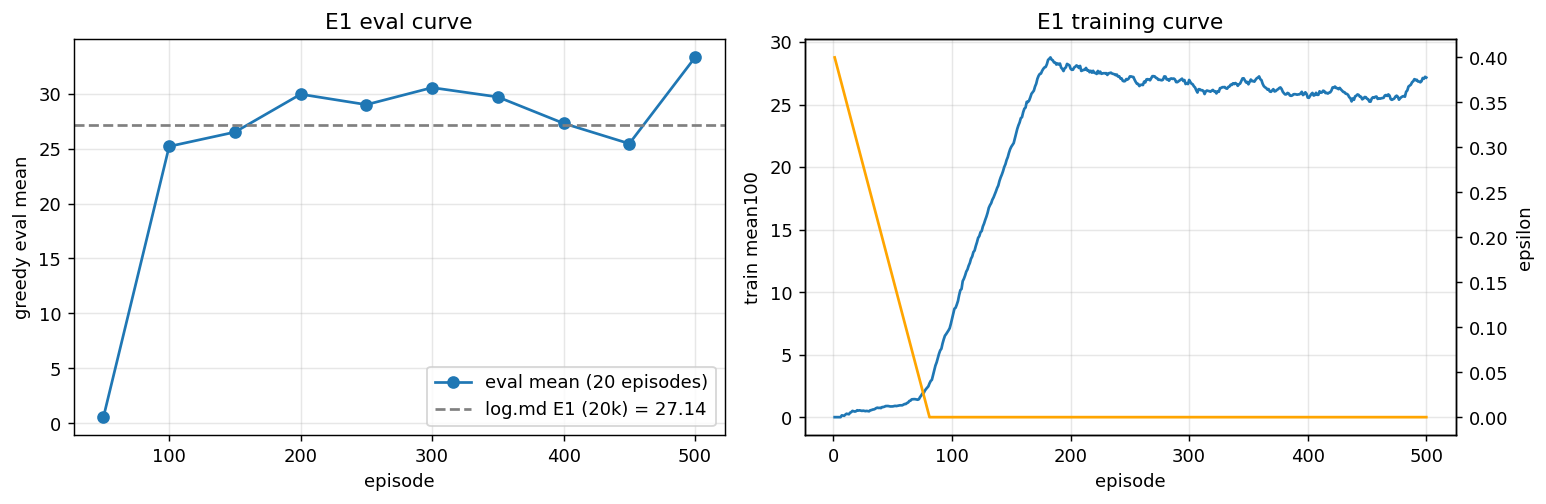

saved: runs/stage1_seed0_colab/e1_curves.png


In [ ]:
#@title 5. 训练曲线
import csv
import pathlib

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

run = pathlib.Path("runs/stage1_seed0_colab")


def read_csv(name):
    with (run / name).open(encoding="utf-8") as f:
        return list(csv.DictReader(f))


evals = read_csv("eval.csv")
train = read_csv("train.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ep = [int(r["episode"]) for r in evals]
axes[0].plot(ep, [float(r["mean_score"]) for r in evals], marker="o",
             label="eval mean (20 episodes)")
axes[0].axhline(27.14, color="gray", linestyle="--",
                label="log.md E1 (20k) = 27.14")
axes[0].set_xlabel("episode")
axes[0].set_ylabel("greedy eval mean")
axes[0].set_title("E1 eval curve")
axes[0].grid(alpha=0.3)
axes[0].legend()

ep = [int(r["episode"]) for r in train]
axes[1].plot(ep, [float(r["mean100"]) for r in train], label="train mean100")
ax2 = axes[1].twinx()
ax2.plot(ep, [float(r["epsilon"]) for r in train], color="orange",
         label="epsilon")
axes[1].set_xlabel("episode")
axes[1].set_ylabel("train mean100")
ax2.set_ylabel("epsilon")
axes[1].set_title("E1 training curve")
axes[1].grid(alpha=0.3)

fig.tight_layout()
out = run / "e1_curves.png"
fig.savefig(out, dpi=130, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(out)))
print("saved:", out)


## 怎么读这份结果

- **训练中 eval（20 局）波动大**：log.md 里同一策略在相邻 checkpoint 上可以差 ±5，
  不要用它下最终结论。
- **看最终 100 局评估**：重点对比 `colab-20k` / `colab-10k` 与 log.md 的
  27.14 / 27.21。Colab 上接近这个量级（大致 23–31）就说明 E1 复刻成功。
- **看死因分布**：E1 的典型结果是 self collision 占 95–99%，
  说明 11 维观察缺少身体形状/距离信息，这就是 Stage 3 的动机。
- **看训练曲线**：log.md 的 E1 在 50–100 局之间出现跃升，175 局后平台化在 25–30。
- 如果 Colab 的数字偏低，优先检查 `config.json` 里的配置是否和上表一致，
  再考虑 CPU 线程数/版本差异，而不是急着调参。
